In [54]:
from getdist import loadMCSamples, plots
import matplotlib.pyplot as plt

chain_root = "/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test"

samples = loadMCSamples(chain_root,  settings={'ignore_rows': 0.3})

print(samples)

/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test.1.txt
/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test.2.txt
/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test.3.txt
/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test.4.txt
Removed 0.3 as burn in


In [55]:
stats = samples.getMargeStats()

for par in samples.getParamNames().names:
    p = stats.parWithName(par.name)

    mean = p.mean
    lower = p.limits[0].lower
    upper = p.limits[0].upper

    print(f"{par.name}:")
    print(f"  Mean = {mean:.5f}")
    print(f"  68% CI = [{lower:.5f}, {upper:.5f}]")
    print(f"  Uncertainty = -{mean-lower:.5f}, +{upper-mean:.5f}")
    print()

H0:
  Mean = 68.03821
  68% CI = [67.80444, 68.26510]
  Uncertainty = -0.23377, +0.22689

omega_b:
  Mean = 0.02223
  68% CI = [0.02203, 0.02244]
  Uncertainty = -0.00020, +0.00020

n_s:
  Mean = 0.96544
  68% CI = [0.96143, 0.96778]
  Uncertainty = -0.00401, +0.00233

logA:
  Mean = 3.04439
  68% CI = [3.03005, 3.05607]
  Uncertainty = -0.01434, +0.01167

tau_reio:
  Mean = 0.05708
  68% CI = [0.05121, 0.06225]
  Uncertainty = -0.00587, +0.00517

Omega_c:
  Mean = 0.25700
  68% CI = [0.25429, 0.25968]
  Uncertainty = -0.00271, +0.00268

beta_axion:
  Mean = 0.06841
  68% CI = [0.05418, 0.08421]
  Uncertainty = -0.01423, +0.01581

log_mphi_H0:
  Mean = -0.30159
  68% CI = [-0.43861, -0.21016]
  Uncertainty = -0.13702, +0.09143

delta_i:
  Mean = 0.78590
  68% CI = [0.73385, 0.85982]
  Uncertainty = -0.05205, +0.07392

A_planck:
  Mean = 0.99993
  68% CI = [0.99811, 1.00150]
  Uncertainty = -0.00182, +0.00157

amp_143:
  Mean = 16.75035
  68% CI = [15.56203, 17.72182]
  Uncertainty = -1

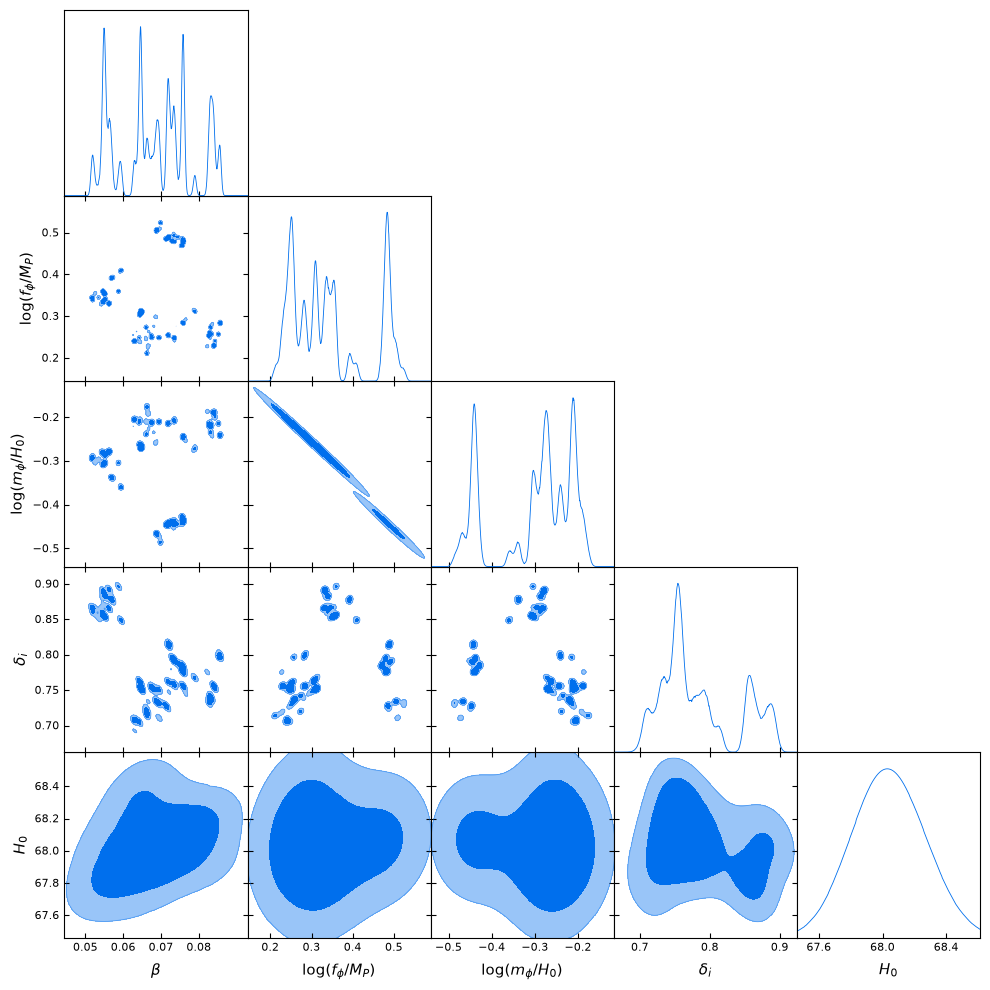

In [56]:
g = plots.get_subplot_plotter()

g.triangle_plot(
    samples,
    ["beta_axion",
     "logf_phi",
     

     
     "log_mphi_H0",
     "delta_i" ,
     "H0"
],
    filled=True
)
plt.savefig('Contour')
plt.show()

In [62]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prefix = "/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test"
files = sorted(glob.glob(prefix + ".[0-9]*.txt"))
print(files)

def load_chain(fname):
    with open(fname) as f:
        header = f.readline().lstrip("#").split()
    df = pd.read_csv(fname, sep=r"\s+", comment="#", names=header, skiprows=1)
    return df

chains = [load_chain(f) for f in files]
print(chains[0].columns.tolist())
print(len(chains), "rows in chain 1")

['/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test.1.txt', '/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test.2.txt', '/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test.3.txt', '/home/imagination/axiclass/yamlfiles/chains/Coupled_axion_test.4.txt']
['weight', 'minuslogpost', 'H0', 'omega_b', 'n_s', 'logA', 'tau_reio', 'Omega_c', 'beta_axion', 'log_mphi_H0', 'delta_i', 'A_planck', 'amp_143', 'amp_217', 'amp_143x217', 'n_143', 'n_217', 'n_143x217', 'calTE', 'calEE', 'A_s', 'Omega_m', 'f_axion', 'logf_phi', 'chi2__BAO', 'chi2__CMB', 'chi2__SN', 'minuslogprior', 'minuslogprior__0', 'chi2', 'chi2__sn.union3', 'chi2__bao.desi_dr2', 'chi2__planck_2018_lowl.TT', 'chi2__planck_2018_lowl.EE', 'chi2__planck_NPIPE_highl_CamSpec.TTTEEE', 'chi2__act_dr6_lenslike.ACTDR6LensLike']
4 rows in chain 1


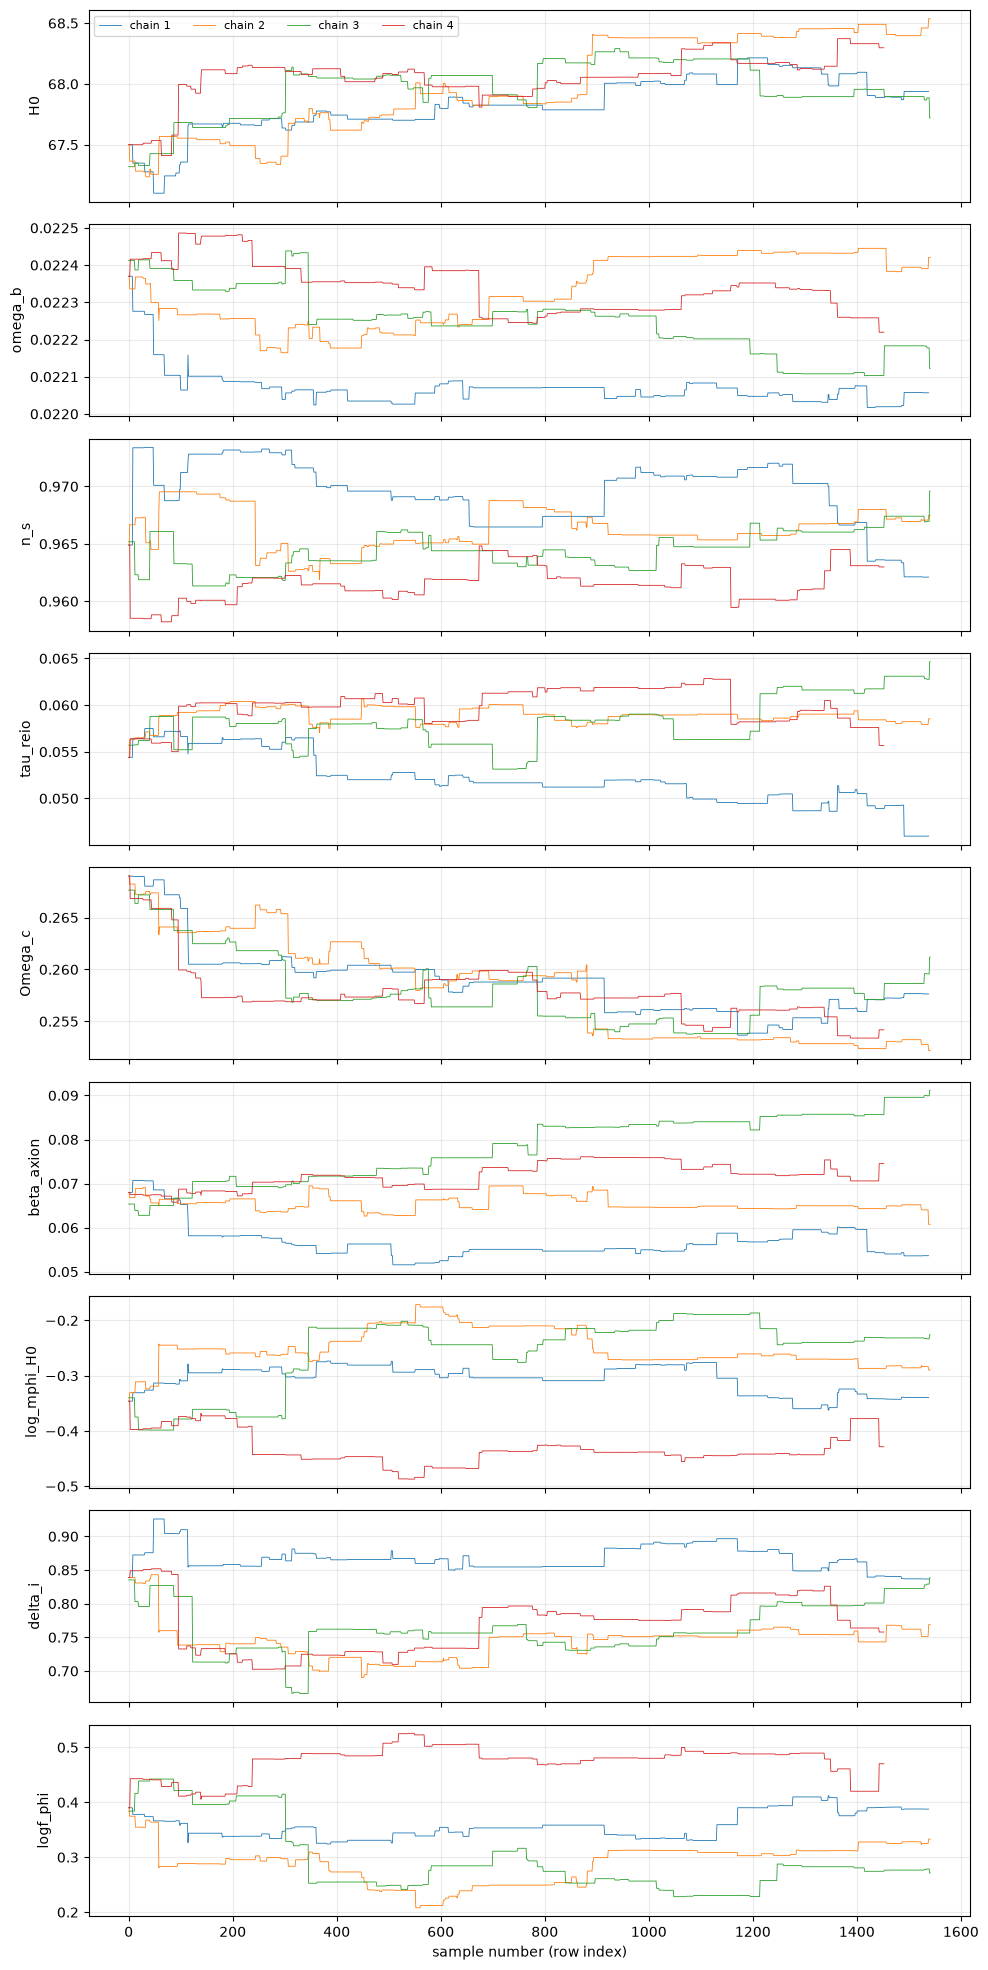

In [63]:
params = ["H0", "omega_b", "n_s", "tau_reio", "Omega_c",
          "beta_axion", "log_mphi_H0", "delta_i","logf_phi"]

fig, axes = plt.subplots(len(params), 1, figsize=(10, 2.2*len(params)), sharex=True)
for ax, p in zip(axes, params):
    for i, df in enumerate(chains):
        ax.plot(df.index, df[p], lw=0.6, label=f"chain {i+1}")
    ax.set_ylabel(p)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("sample number (row index)")
axes[0].legend(ncol=len(chains), fontsize=8)

plt.tight_layout()
plt.savefig('chains')
plt.show()

chain 1: acceptance ~ 0.429
chain 2: acceptance ~ 0.432
chain 3: acceptance ~ 0.437
chain 4: acceptance ~ 0.414


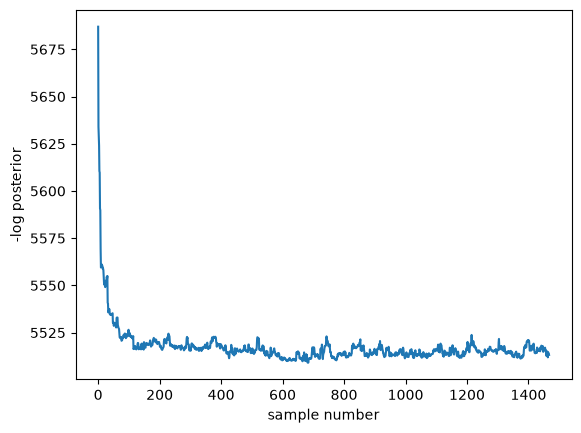

In [61]:
for i, df in enumerate(chains):
    print(f"chain {i+1}: acceptance ~ {len(df)/df['weight'].sum():.3f}")

plt.plot(chains[0]["minuslogpost"])
plt.ylabel("-log posterior"); plt.xlabel("sample number"); plt.show()

Live-point array shape: (8280, 33)


IndexError: list index out of range

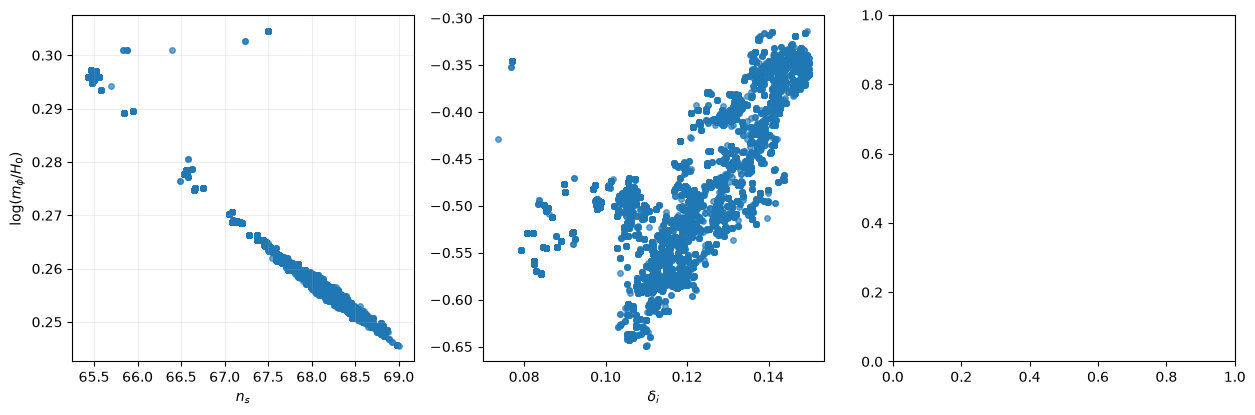

In [38]:
import numpy as np
import matplotlib.pyplot as plt

file_path = "/home/imagination/axiclass/yamlfiles/chains/CA.1.txt"


# Read the current snapshot of the live points
live = np.loadtxt(file_path, ndmin=2)

print("Live-point array shape:", live.shape)

# Provisional mapping: verify against PolyChord metadata
params = [
    r"$H_0$",
    r"$\omega_b$",
    r"$n_s$",
    r"$\log(10^{10}A_s)$",
    r"$\tau_{\rm reio}$",
    r"$\Omega_c$",
    r"$\beta_{\rm axion}$",
    r"$\log(m_\phi/H_0)$",
    r"$\delta_i$"
]

# Three scientifically useful diagnostic pairs
pairs = [
    (2, 7),  # H0 vs Omega_c
    (8, 9),  # beta_axion vs log(m_phi/H0)
    (7, 10),  # Omega_c vs delta_i
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (i, j) in zip(axes, pairs):
    ax.scatter(
        live[:, i], live[:, j],
        s=16, alpha=0.65
    )
    ax.set_xlabel(params[i])
    ax.set_ylabel(params[j])
    ax.grid(alpha=0.2)

fig.suptitle(
    "Current PolyChord live points — diagnostic only"
)
plt.tight_layout()
plt.show()